In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!unzip /content/drive/MyDrive/ImageSegmentationYOLOv8-20240221T101157Z-001.zip

Archive:  /content/drive/MyDrive/ImageSegmentationYOLOv8-20240221T101157Z-001.zip
   creating: ImageSegmentationYOLOv8/all_info/.ipynb_checkpoints/
   creating: ImageSegmentationYOLOv8/all_info/images/.ipynb_checkpoints/
  inflating: ImageSegmentationYOLOv8/all_info/images/test/Sub(93-164)0017.png  
  inflating: ImageSegmentationYOLOv8/all_info/images/test/Sub(93-164)0018.png  
  inflating: ImageSegmentationYOLOv8/all_info/images/test/Sub(93-164)0001.png  
  inflating: ImageSegmentationYOLOv8/all_info/images/test/Sub(93-164)0012.png  
  inflating: ImageSegmentationYOLOv8/all_info/images/test/Sub(93-164)0020.png  
   creating: ImageSegmentationYOLOv8/all_info/images/val/.ipynb_checkpoints/
  inflating: ImageSegmentationYOLOv8/all_info/images/test/Sub(93-164)0010.png  
   creating: ImageSegmentationYOLOv8/all_info/images/train/.ipynb_checkpoints/
  inflating: ImageSegmentationYOLOv8/all_info/images/test/Sub(93-164)0019.png  
  inflating: ImageSegmentationYOLOv8/all_info/images/test/Sub(9

In [ ]:
import json

# Load the data from the uploaded JSON file
with open("/content/train.json", "r") as file:
    data = json.load(file)

# Initialize the COCO format dictionary
coco_format = {
    "info": data["info"],
    "images": [],
    "annotations": [],
    "categories": data["categories"]
}

# Mapping from original image IDs to COCO image IDs
image_id_mapping = {}

# Process images
for idx, image in enumerate(data["images"], start=1):
    image_id_mapping[image["id"]] = idx
    coco_image = {
        "id": idx,
        "width": image["width"],
        "height": image["height"],
        "file_name": image["file_name"]
    }
    coco_format["images"].append(coco_image)

# Process annotations
for idx, annotation in enumerate(data["annotations"], start=1):
    coco_annotation = {
        "id": idx,
        "image_id": image_id_mapping[annotation["image_id"]],
        "category_id": 1,  # Assuming all annotations belong to a single category
        "segmentation": annotation["segmentation"],
        "area": annotation["area"],
        "bbox": annotation["bbox"],
        "iscrowd": 0  # Assuming this is single object segmentation
    }
    coco_format["annotations"].append(coco_annotation)

# Save the COCO format data to a new JSON file
coco_file_path = "/content/train_coco.json"
with open(coco_file_path, "w") as file:
    json.dump(coco_format, file, indent=4)

coco_file_path


'/content/train_coco.json'

In [2]:
!python -m pip install pyyaml==5.1
import sys, os, distutils.core
# Note: This is a faster way to install detectron2 in Colab, but it does not include all functionalities (e.g. compiled operators).
# See https://detectron2.readthedocs.io/tutorials/install.html for full installation instructions
!git clone 'https://github.com/facebookresearch/detectron2'
dist = distutils.core.run_setup("./detectron2/setup.py")
!python -m pip install {' '.join([f"'{x}'" for x in dist.install_requires])}
sys.path.insert(0, os.path.abspath('./detectron2'))

# Properly install detectron2. (Please do not install twice in both ways)
# !python -m pip install 'git+https://github.com/facebookresearch/detectron2.git'

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 274.2/274.2 kB 6.9 MB/s eta 0:00:00
  error: subprocess-exited-with-error
  
  × python setup.py egg_info did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Preparing metadata (setup.py) ... error
error: metadata-generation-failed

× Encountered error while generating package metadata.
╰─> See above for output.

note: This is an issue with the package mentioned above, not pip.
hint: See above for details.
Cloning into 'detectron2'...
remote: Enumerating objects: 15359, done.
remote: Counting objects: 100% (84/84), done.
remote: Compressing objects: 100% (68/68), done.
remote: Total 15359 (delta 31), reused 43 (delta 16), pack-reused 15275
Receiving objects: 100% (15359/15359), 6.23 MiB | 19.34 MiB/s, done.
Resolving deltas: 100% (11145/11145), done.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 2.5 MB/s eta 0:00:00
  

In [4]:
import torch, detectron2
!nvcc --version
TORCH_VERSION = ".".join(torch.__version__.split(".")[:2])
CUDA_VERSION = torch.__version__.split("+")[-1]
print("torch: ", TORCH_VERSION, "; cuda: ", CUDA_VERSION)
print("detectron2:", detectron2.__version__)

nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2023 NVIDIA Corporation
Built on Tue_Aug_15_22:02:13_PDT_2023
Cuda compilation tools, release 12.2, V12.2.140
Build cuda_12.2.r12.2/compiler.33191640_0
torch:  2.1 ; cuda:  cu121
detectron2: 0.6


In [3]:
# Some basic setup:
# Setup detectron2 logger
import detectron2
from detectron2.utils.logger import setup_logger
setup_logger()

# import some common libraries
import numpy as np
import os, json, cv2, random
from google.colab.patches import cv2_imshow

# import some common detectron2 utilities
from detectron2 import model_zoo
from detectron2.engine import DefaultPredictor
from detectron2.config import get_cfg
from detectron2.utils.visualizer import Visualizer
from detectron2.data import MetadataCatalog, DatasetCatalog

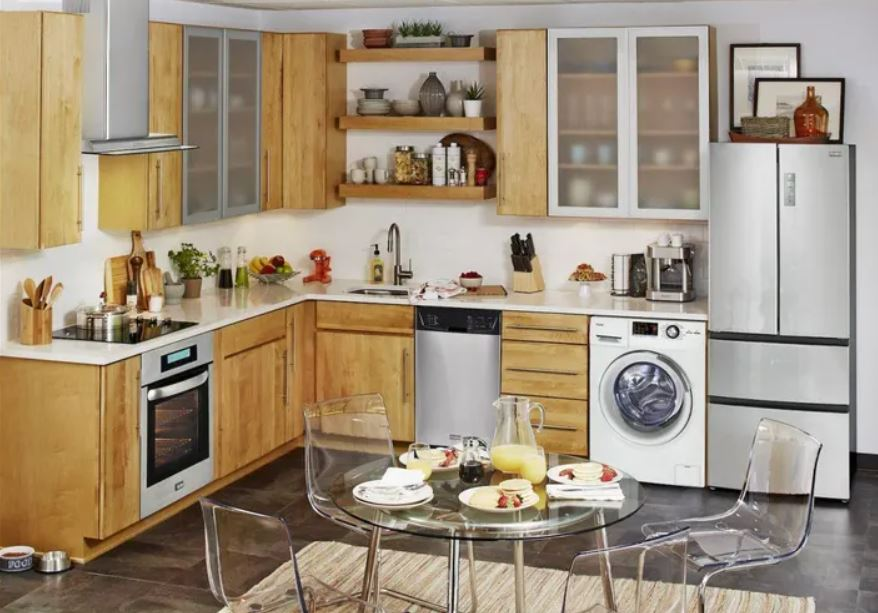

In [5]:
im = cv2.imread("/content/indir.png")
cv2_imshow(im)

In [6]:
cfg = get_cfg()
cfg.merge_from_file(model_zoo.get_config_file("COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml"))
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.5  # set threshold for this model
# Find a model from detectron2's model zoo.  https://github.com/facebookresearch/detectron2/blob/main/MODEL_ZOO.md
cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url("COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml")
predictor = DefaultPredictor(cfg)
outputs = predictor(im)

[02/21 10:42:41 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from https://dl.fbaipublicfiles.com/detectron2/COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x/137849600/model_final_f10217.pkl ...


model_final_f10217.pkl: 178MB [00:01, 172MB/s]                           
/usr/local/lib/python3.10/dist-packages/torch/functional.py:504: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at ../aten/src/ATen/native/TensorShape.cpp:3526.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


In [7]:

# look at the outputs - tensors and bounding boxes.
print(outputs["instances"].pred_classes)
print(outputs["instances"].pred_boxes)

tensor([72, 39, 69, 58, 39, 44, 75, 43, 45, 71, 60, 43, 45, 41, 41, 43, 58, 45,
        43, 44, 56, 47, 41, 69, 45, 70, 43, 44, 45, 39, 69, 43, 75, 39, 41, 41,
        47, 43, 58, 41, 75], device='cuda:0')
Boxes(tensor([[703.4380, 144.0455, 857.8510, 506.5736],
        [369.6783, 243.7499, 383.7241, 284.1012],
        [136.9388, 337.5629, 217.0721, 517.6235],
        [166.9899, 242.3348, 219.8243, 300.1612],
        [235.3407, 247.5448, 248.5214, 288.5075],
        [ 23.8118, 277.7756,  34.6548, 302.0351],
        [419.3823,  72.0066, 445.4690, 116.3277],
        [510.5142, 235.3142, 519.6863, 255.0639],
        [389.8859,  99.1747, 420.6154, 115.4872],
        [346.6928, 285.2446, 409.4030, 297.5113],
        [247.1815, 432.7683, 803.7862, 603.8624],
        [523.2750, 254.2419, 533.3571, 272.5920],
        [357.8499,  99.9275, 391.2559, 114.6091],
        [596.2269, 143.3925, 614.7797, 164.4311],
        [569.3777, 143.7829, 586.9908, 163.6248],
        [525.9772, 234.5415, 534.9613,

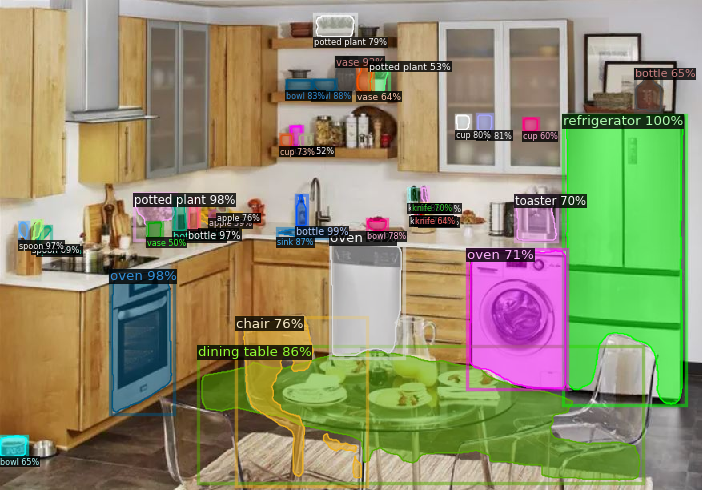

In [8]:

# We can use `Visualizer` to draw the predictions on the image.
v = Visualizer(im[:, :, ::-1], MetadataCatalog.get(cfg.DATASETS.TRAIN[0]), scale=0.8)
out = v.draw_instance_predictions(outputs["instances"].to("cpu"))
cv2_imshow(out.get_image()[:, :, ::-1])

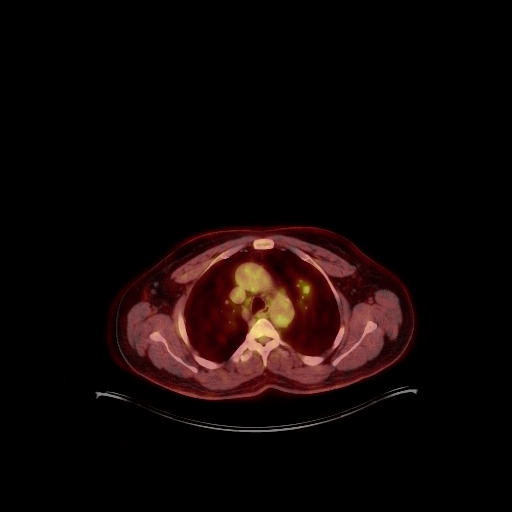

In [9]:
sci_im = cv2.imread("/content/drive/MyDrive/ImageSegmentationYOLOv8/all_info/images/train/(103-176)0023.png")
cv2_imshow(sci_im)

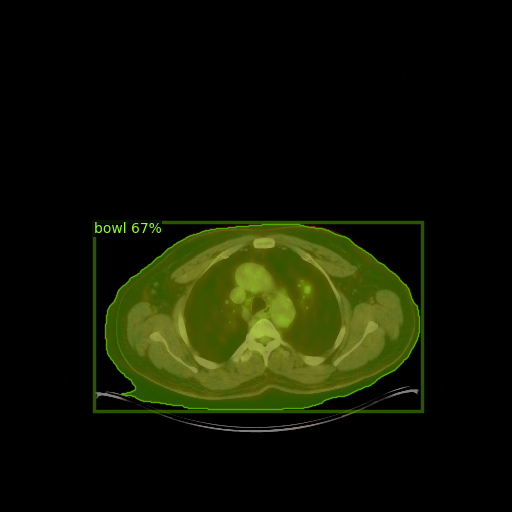

In [10]:
sci_outputs = predictor(sci_im)
sci_v = Visualizer(sci_im[:, :, ::-1], MetadataCatalog.get(cfg.DATASETS.TRAIN[0]))
sci_out = sci_v.draw_instance_predictions(sci_outputs["instances"].to("cpu"))
cv2_imshow(sci_out.get_image()[:, :, ::-1])


In [11]:
from detectron2.data.datasets import register_coco_instances
register_coco_instances("my_dataset_train", {}, "/content/drive/MyDrive/ImageSegmentationYOLOv8/all_info/images/train/train_coco.json", "/content/drive/MyDrive/ImageSegmentationYOLOv8/all_info/images/train")
register_coco_instances("my_dataset_val", {}, "/content/drive/MyDrive/ImageSegmentationYOLOv8/all_info/images/val/val_coco.json", "/content/drive/MyDrive/ImageSegmentationYOLOv8/all_info/images/val")



In [12]:
train_metadata = MetadataCatalog.get("my_dataset_train")
train_dataset_dicts = DatasetCatalog.get("my_dataset_train")

[02/21 10:42:53 d2.data.datasets.coco]: Loading /content/drive/MyDrive/ImageSegmentationYOLOv8/all_info/images/train/train_coco.json takes 1.18 seconds.
[02/21 10:42:53 d2.data.datasets.coco]: Loaded 789 images in COCO format from /content/drive/MyDrive/ImageSegmentationYOLOv8/all_info/images/train/train_coco.json


In [13]:
val_metadata = MetadataCatalog.get("my_dataset_val")
val_dataset_dicts = DatasetCatalog.get("my_dataset_val")


[02/21 10:42:55 d2.data.datasets.coco]: Loading /content/drive/MyDrive/ImageSegmentationYOLOv8/all_info/images/val/val_coco.json takes 1.79 seconds.
[02/21 10:42:55 d2.data.datasets.coco]: Loaded 198 images in COCO format from /content/drive/MyDrive/ImageSegmentationYOLOv8/all_info/images/val/val_coco.json


In [15]:
from matplotlib import pyplot as plt

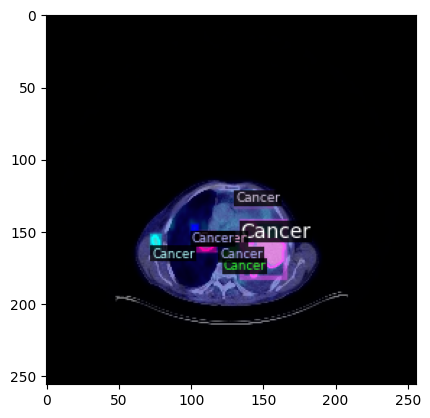

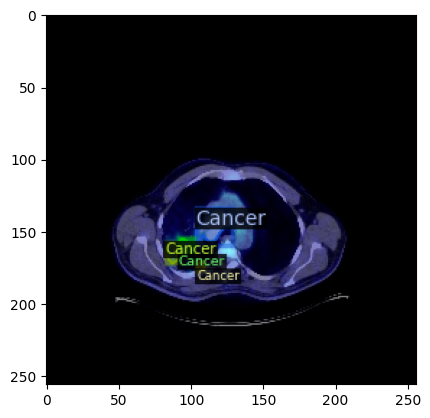

In [16]:
from matplotlib import pyplot as plt
# Visualize some random samples
for d in random.sample(train_dataset_dicts, 2):
    img = cv2.imread(d["file_name"])
    visualizer = Visualizer(img[:, :, ::-1], metadata=train_metadata, scale=0.5)
    vis = visualizer.draw_dataset_dict(d)
    plt.imshow(vis.get_image()[:, :, ::-1])
    plt.show()

In [17]:
from detectron2.engine import DefaultTrainer

cfg = get_cfg()
cfg.OUTPUT_DIR = "/content/drive/MyDrive/Detectron2_Models"
cfg.merge_from_file(model_zoo.get_config_file("COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml"))
cfg.DATASETS.TRAIN = ("my_dataset_train",)
cfg.DATASETS.TEST = ("my_dataset_val",)
cfg.DATALOADER.NUM_WORKERS = 2
cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url("COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml")  # Let training initialize from model zoo
cfg.SOLVER.IMS_PER_BATCH = 2  # This is the real "batch size" commonly known to deep learning people
cfg.SOLVER.BASE_LR = 0.00025  # pick a good LR
cfg.SOLVER.MAX_ITER = 1500    # 1000 iterations seems good enough for this dataset
cfg.SOLVER.STEPS = []        # do not decay learning rate
cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE = 256   # Default is 512, using 256 for this dataset.
cfg.MODEL.ROI_HEADS.NUM_CLASSES = 1
# NOTE: this config means the number of classes, without the background. Do not use num_classes+1 here.

os.makedirs(cfg.OUTPUT_DIR, exist_ok=True)
trainer = DefaultTrainer(cfg) #Create an instance of of DefaultTrainer with the given congiguration
trainer.resume_or_load(resume=False) #Load a pretrained model if available (resume training) or start training from scratch if no pretrained model is available

[02/21 10:43:19 d2.engine.defaults]: Model:
GeneralizedRCNN(
  (backbone): FPN(
    (fpn_lateral2): Conv2d(256, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral3): Conv2d(512, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output3): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral4): Conv2d(1024, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output4): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral5): Conv2d(2048, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output5): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (top_block): LastLevelMaxPool()
    (bottom_up): ResNet(
      (stem): BasicStem(
        (conv1): Conv2d(
          3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False
          (norm): FrozenBatchNorm2d(num_features=64, eps=1e-05)
        )
      )
      (res

roi_heads.box_predictor.bbox_pred.{bias, weight}
roi_heads.box_predictor.cls_score.{bias, weight}
roi_heads.mask_head.predictor.{bias, weight}


In [18]:
trainer.train() #Start the training process

[02/21 10:43:31 d2.engine.train_loop]: Starting training from iteration 0
[02/21 10:43:50 d2.utils.events]:  eta: 0:22:32  iter: 19  total_loss: 3.027  loss_cls: 0.7671  loss_box_reg: 0.07697  loss_mask: 0.6927  loss_rpn_cls: 1.111  loss_rpn_loc: 0.2746    time: 0.8477  last_time: 1.1261  data_time: 0.5464  last_data_time: 0.8179   lr: 4.9953e-06  max_mem: 1963M
[02/21 10:44:08 d2.utils.events]:  eta: 0:20:16  iter: 39  total_loss: 1.773  loss_cls: 0.6338  loss_box_reg: 0.1313  loss_mask: 0.6875  loss_rpn_cls: 0.2403  loss_rpn_loc: 0.0761    time: 0.8112  last_time: 0.7705  data_time: 0.4542  last_data_time: 0.5241   lr: 9.9902e-06  max_mem: 1963M
[02/21 10:44:25 d2.utils.events]:  eta: 0:20:19  iter: 59  total_loss: 1.85  loss_cls: 0.4551  loss_box_reg: 0.298  loss_mask: 0.677  loss_rpn_cls: 0.334  loss_rpn_loc: 0.1476    time: 0.8237  last_time: 0.8907  data_time: 0.5260  last_data_time: 0.5577   lr: 1.4985e-05  max_mem: 1963M
[02/21 10:44:41 d2.utils.events]:  eta: 0:19:42  iter: 79

In [19]:
import yaml
# Save the configuration to a config.yaml file
# Save the configuration to a config.yaml file
config_yaml_path = "/content/drive/MyDrive/Detectron2_Models/config.yaml"
with open(config_yaml_path, 'w') as file:
    yaml.dump(cfg, file)

In [20]:
# Inference should use the config with parameters that are used in training
# cfg now already contains everything we've set previously. We changed it a little bit for inference:
cfg.MODEL.WEIGHTS = os.path.join(cfg.OUTPUT_DIR, "model_final.pth")  # path to the model we just trained
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.5   # set a custom testing threshold
predictor = DefaultPredictor(cfg)



[02/21 10:55:26 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/drive/MyDrive/Detectron2_Models/model_final.pth ...


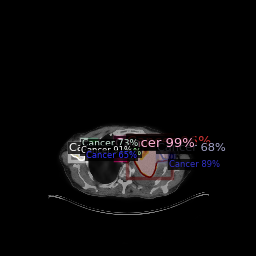

In [21]:
from detectron2.utils.visualizer import ColorMode

for d in random.sample(val_dataset_dicts, 1):    #select number of images for display
    im = cv2.imread(d["file_name"])
    outputs = predictor(im)
    v = Visualizer(im[:, :, ::-1],
                   metadata=val_metadata,
                   scale=0.5,
                   instance_mode=ColorMode.IMAGE_BW   # remove the colors of unsegmented pixels. This option is only available for segmentation models
    )
    out = v.draw_instance_predictions(outputs["instances"].to("cpu"))
    cv2_imshow(out.get_image()[:, :, ::-1])

In [ ]:
from detectron2.evaluation import COCOEvaluator, inference_on_dataset
from detectron2.data import build_detection_test_loader
evaluator = COCOEvaluator("my_dataset_val", output_dir="./output")
val_loader = build_detection_test_loader(cfg, "my_dataset_val")
print(inference_on_dataset(predictor.model, val_loader, evaluator))
# another equivalent way to evaluate the model is to use `trainer.test`

[02/21 08:04:46 d2.evaluation.coco_evaluation]: Fast COCO eval is not built. Falling back to official COCO eval.
[02/21 08:04:46 d2.data.datasets.coco]: Loaded 198 images in COCO format from /content/drive/MyDrive/ImageSegmentationYOLOv8/all_info/images/val/val_coco.json
[02/21 08:04:46 d2.data.build]: Distribution of instances among all 1 categories:
|  category  | #instances   |
|:----------:|:-------------|
|   Cancer   | 540          |
|            |              |
[02/21 08:04:46 d2.data.dataset_mapper]: [DatasetMapper] Augmentations used in inference: [ResizeShortestEdge(short_edge_length=(800, 800), max_size=1333, sample_style='choice')]
[02/21 08:04:46 d2.data.common]: Serializing the dataset using: <class 'detectron2.data.common._TorchSerializedList'>
[02/21 08:04:46 d2.data.common]: Serializing 198 elements to byte tensors and concatenating them all ...
[02/21 08:04:46 d2.data.common]: Serialized dataset takes 0.70 MiB
[02/21 08:04:46 d2.evaluation.evaluator]: Start inference

In [22]:
from detectron2.evaluation import COCOEvaluator, inference_on_dataset
from detectron2.data import build_detection_test_loader

# COCOEvaluator ile değerlendirme için bir evaluator oluşturun
evaluator = COCOEvaluator("my_dataset_val", cfg, False, output_dir=cfg.OUTPUT_DIR)

# Değerlendirme için test dataloader'ı oluşturun
val_loader = build_detection_test_loader(cfg, "my_dataset_val")

# Modeli kullanarak değerlendirme yapın ve metrikleri elde edin
evaluation_results = inference_on_dataset(trainer.model, val_loader, evaluator)

# Değerlendirme sonuçlarını yazdırın
print(evaluation_results)


[02/21 10:55:46 d2.evaluation.coco_evaluation]: Fast COCO eval is not built. Falling back to official COCO eval.
WARNING [02/21 10:55:46 d2.evaluation.coco_evaluation]: COCO Evaluator instantiated using config, this is deprecated behavior. Please pass in explicit arguments instead.
[02/21 10:55:46 d2.data.datasets.coco]: Loaded 198 images in COCO format from /content/drive/MyDrive/ImageSegmentationYOLOv8/all_info/images/val/val_coco.json
[02/21 10:55:46 d2.data.dataset_mapper]: [DatasetMapper] Augmentations used in inference: [ResizeShortestEdge(short_edge_length=(800, 800), max_size=1333, sample_style='choice')]
[02/21 10:55:46 d2.data.common]: Serializing the dataset using: <class 'detectron2.data.common._TorchSerializedList'>
[02/21 10:55:46 d2.data.common]: Serializing 198 elements to byte tensors and concatenating them all ...
[02/21 10:55:46 d2.data.common]: Serialized dataset takes 0.70 MiB
[02/21 10:55:46 d2.evaluation.evaluator]: Start inference on 198 batches
[02/21 10:55:51 

In [23]:
from detectron2.evaluation import COCOEvaluator

# Test veri setini yapılandırma dosyasına ekleyin
cfg.DATASETS.TEST = ("my_dataset_val", )

# Değerlendiriciyi oluşturun
evaluator = COCOEvaluator("my_dataset_val", cfg, False, output_dir="/content/drive/MyDrive/Detectron2_Models/evaluation")

# Modeli test edin ve değerlendirme sonuçlarını alın
results = trainer.test(cfg, trainer.model, evaluators=[evaluator])


[02/21 10:58:03 d2.evaluation.coco_evaluation]: Fast COCO eval is not built. Falling back to official COCO eval.
WARNING [02/21 10:58:03 d2.evaluation.coco_evaluation]: COCO Evaluator instantiated using config, this is deprecated behavior. Please pass in explicit arguments instead.
[02/21 10:58:03 d2.data.datasets.coco]: Loaded 198 images in COCO format from /content/drive/MyDrive/ImageSegmentationYOLOv8/all_info/images/val/val_coco.json
[02/21 10:58:03 d2.data.dataset_mapper]: [DatasetMapper] Augmentations used in inference: [ResizeShortestEdge(short_edge_length=(800, 800), max_size=1333, sample_style='choice')]
[02/21 10:58:03 d2.data.common]: Serializing the dataset using: <class 'detectron2.data.common._TorchSerializedList'>
[02/21 10:58:03 d2.data.common]: Serializing 198 elements to byte tensors and concatenating them all ...
[02/21 10:58:03 d2.data.common]: Serialized dataset takes 0.70 MiB
[02/21 10:58:03 d2.evaluation.evaluator]: Start inference on 198 batches
[02/21 10:58:05 

In [24]:
new_im = cv2.imread("/content/Substack (106-176)0006.png")
outputs  = predictor(new_im)

# We can use `Visualizer` to draw the predictions on the image.
v = Visualizer(new_im[:, :, ::-1], metadata=train_metadata)
out = v.draw_instance_predictions(outputs["instances"].to("cpu"))

cv2_imshow(out.get_image()[:, :, ::-1])


AttributeError: 'NoneType' object has no attribute 'shape'

In [ ]:
# Directory path to the input images folder
input_images_directory = "/content/drive/MyDrive/ImageSegmentationYOLOv8/all_info/images/test"

# Output directory where the segmented images will be saved
output_directory = "/content/çıkış"  # Replace this with the path to your desired output directory

# Loop over the images in the input folder
for image_filename in os.listdir(input_images_directory):
    image_path = os.path.join(input_images_directory, image_filename)
    new_im = cv2.imread(image_path)

    # Perform prediction on the new image
    outputs = predictor(new_im)  # Format is documented at https://detectron2.readthedocs.io/tutorials/models.html#model-output-format

    # We can use `Visualizer` to draw the predictions on the image.
    v = Visualizer(new_im[:, :, ::-1], metadata=train_metadata)
    out = v.draw_instance_predictions(outputs["instances"].to("cpu"))

    # Create the output filename with _result extension
    result_filename = os.path.splitext(image_filename)[0] + "_result.png"
    output_path = os.path.join(output_directory, result_filename)

    # Save the segmented image
    cv2.imwrite(output_path, out.get_image()[:, :, ::-1])

print("Segmentation of all images completed.")

Segmentation of all images completed.


In [ ]:
import os
import cv2
import numpy as np
from detectron2.utils.visualizer import ColorMode

# Directory path to the input images folder
input_images_directory = "/content/drive/MyDrive/ImageSegmentationYOLOv8/all_info/images/test"

# Output directory where the segmented images will be saved
output_directory = "/content/drive/MyDrive/çıkış"

if not os.path.exists(output_directory):
    os.makedirs(output_directory)

# Loop over the images in the input folder
for image_filename in os.listdir(input_images_directory):
    image_path = os.path.join(input_images_directory, image_filename)
    img = cv2.imread(image_path)

    # Perform prediction on the image
    outputs = predictor(img)

    # Convert binary masks to uint8
    masks = (outputs["instances"].pred_masks.to("cpu").numpy() * 255).astype(np.uint8)

    for mask in masks:
        contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(img, contours, -1, (0, 255, 0), 0)

    # Create the output filename with _contour extension
    result_filename = os.path.splitext(image_filename)[0] + "_contour.png"
    output_path = os.path.join(output_directory, result_filename)

    # Save the image with contours
    cv2.imwrite(output_path, img)

print("Contour drawing of all images completed.")


Contour drawing of all images completed.


#mask_rcnn_R_101_FPN_3x

In [5]:
from detectron2.config import get_cfg
from detectron2 import model_zoo
from detectron2.engine import DefaultTrainer
from detectron2.evaluation import COCOEvaluator, inference_on_dataset
from detectron2.data import build_detection_test_loader
from detectron2.utils.events import EventWriter, get_event_storage

# Veri setlerini kaydet
from detectron2.data.datasets import register_coco_instances
register_coco_instances("my_dataset_train", {}, "/content/drive/MyDrive/ImageSegmentationYOLOv8/all_info/images/train/train_coco.json", "/content/drive/MyDrive/ImageSegmentationYOLOv8/all_info/images/train")
register_coco_instances("my_dataset_val", {}, "/content/drive/MyDrive/ImageSegmentationYOLOv8/all_info/images/val/val_coco.json", "/content/drive/MyDrive/ImageSegmentationYOLOv8/all_info/images/val")

# Model konfigürasyonunu ayarla
cfg = get_cfg()
cfg.merge_from_file(model_zoo.get_config_file("COCO-InstanceSegmentation/mask_rcnn_R_101_FPN_3x.yaml"))
cfg.DATASETS.TRAIN = ("my_dataset_train",)
cfg.DATASETS.TEST = ("my_dataset_val",)
cfg.DATALOADER.NUM_WORKERS = 4
cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url("COCO-InstanceSegmentation/mask_rcnn_R_101_FPN_3x.yaml")
cfg.SOLVER.IMS_PER_BATCH = 4  # Daha yüksek bir batch size, GPU belleği izin veriyorsa artırılabilir
cfg.SOLVER.BASE_LR = 0.002  # Hiperparametre optimizasyonu ile ayarlanabilir
cfg.SOLVER.MAX_ITER = 3000  # Daha fazla iterasyon, daha iyi sonuçlar verebilir ancak aşırı uyuma dikkat et
cfg.SOLVER.STEPS = []  # Öğrenme oranı düşüş adımlarını ayarlayın, gerekirse
cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE = 128  # (varsayılan: 512)
cfg.MODEL.ROI_HEADS.NUM_CLASSES = 1  # Sadece 'cancer' sınıfı var

# Özel kayıp fonksiyonları ve düzenleştirmeler için Hook oluştur
class MyTrainer(DefaultTrainer):
    @classmethod
    def build_evaluator(cls, cfg, dataset_name, output_folder=None):
        return COCOEvaluator(dataset_name, cfg, True, output_folder)

    def build_hooks(self):
        hooks = super().build_hooks()
        # Özel hook'larınızı veya kayıp fonksiyonu düzenlemelerinizi buraya ekleyin
        return hooks

# Modeli eğit
trainer = MyTrainer(cfg)
trainer.resume_or_load(resume=False)
trainer.train()

# Model değerlendirme
evaluator = COCOEvaluator("my_dataset_val", cfg, False, output_dir="./output/")
val_loader = build_detection_test_loader(cfg, "my_dataset_val")
print(inference_on_dataset(trainer.model, val_loader, evaluator))

# Hata analizi
# Modelin yanlış sınıflandırdığı veya düşük güven ile sınıflandırdığı örnekleri inceleyin
# Bu, modelinizi daha da iyileştirmek için ipuçları verebilir


[02/21 11:16:12 d2.engine.defaults]: Model:
GeneralizedRCNN(
  (backbone): FPN(
    (fpn_lateral2): Conv2d(256, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral3): Conv2d(512, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output3): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral4): Conv2d(1024, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output4): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral5): Conv2d(2048, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output5): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (top_block): LastLevelMaxPool()
    (bottom_up): ResNet(
      (stem): BasicStem(
        (conv1): Conv2d(
          3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False
          (norm): FrozenBatchNorm2d(num_features=64, eps=1e-05)
        )
      )
      (res

/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:557: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(
model_final_a3ec72.pkl: 254MB [00:01, 130MB/s]                           
roi_heads.box_predictor.bbox_pred.{bias, weight}
roi_heads.box_predictor.cls_score.{bias, weight}
roi_heads.mask_head.predictor.{bias, weight}


[02/21 11:16:16 d2.engine.train_loop]: Starting training from iteration 0


/usr/local/lib/python3.10/dist-packages/torch/functional.py:504: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at ../aten/src/ATen/native/TensorShape.cpp:3526.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


[02/21 11:16:39 d2.utils.events]:  eta: 0:41:44  iter: 19  total_loss: 2.411  loss_cls: 0.5695  loss_box_reg: 0.3209  loss_mask: 0.6882  loss_rpn_cls: 0.6202  loss_rpn_loc: 0.2356    time: 0.8572  last_time: 0.9831  data_time: 0.1097  last_data_time: 0.0120   lr: 3.9962e-05  max_mem: 4238M
[02/21 11:17:01 d2.utils.events]:  eta: 0:43:46  iter: 39  total_loss: 1.65  loss_cls: 0.3698  loss_box_reg: 0.4006  loss_mask: 0.6484  loss_rpn_cls: 0.05472  loss_rpn_loc: 0.1598    time: 0.8749  last_time: 0.8394  data_time: 0.0140  last_data_time: 0.0161   lr: 7.9922e-05  max_mem: 4239M
[02/21 11:17:19 d2.utils.events]:  eta: 0:45:21  iter: 59  total_loss: 1.403  loss_cls: 0.2993  loss_box_reg: 0.3735  loss_mask: 0.558  loss_rpn_cls: 0.05056  loss_rpn_loc: 0.1218    time: 0.8951  last_time: 0.9877  data_time: 0.0191  last_data_time: 0.0112   lr: 0.00011988  max_mem: 4239M
[02/21 11:17:38 d2.utils.events]:  eta: 0:44:54  iter: 79  total_loss: 1.369  loss_cls: 0.2827  loss_box_reg: 0.5099  loss_mask

/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:557: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(


[02/21 12:04:57 d2.evaluation.evaluator]: Inference done 11/198. Dataloading: 0.0850 s/iter. Inference: 0.1103 s/iter. Eval: 0.0113 s/iter. Total: 0.2066 s/iter. ETA=0:00:38
[02/21 12:05:03 d2.evaluation.evaluator]: Inference done 39/198. Dataloading: 0.0775 s/iter. Inference: 0.1105 s/iter. Eval: 0.0085 s/iter. Total: 0.1967 s/iter. ETA=0:00:31
[02/21 12:05:08 d2.evaluation.evaluator]: Inference done 66/198. Dataloading: 0.0807 s/iter. Inference: 0.1080 s/iter. Eval: 0.0059 s/iter. Total: 0.1947 s/iter. ETA=0:00:25
[02/21 12:05:13 d2.evaluation.evaluator]: Inference done 93/198. Dataloading: 0.0791 s/iter. Inference: 0.1078 s/iter. Eval: 0.0051 s/iter. Total: 0.1920 s/iter. ETA=0:00:20
[02/21 12:05:18 d2.evaluation.evaluator]: Inference done 122/198. Dataloading: 0.0758 s/iter. Inference: 0.1075 s/iter. Eval: 0.0045 s/iter. Total: 0.1880 s/iter. ETA=0:00:14
[02/21 12:05:23 d2.evaluation.evaluator]: Inference done 150/198. Dataloading: 0.0760 s/iter. Inference: 0.1072 s/iter. Eval: 0.0

/usr/local/lib/python3.10/dist-packages/torch/utils/data/dataloader.py:557: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(


[02/21 12:05:34 d2.evaluation.evaluator]: Inference done 11/198. Dataloading: 0.0011 s/iter. Inference: 0.1105 s/iter. Eval: 0.0102 s/iter. Total: 0.1219 s/iter. ETA=0:00:22
[02/21 12:05:39 d2.evaluation.evaluator]: Inference done 50/198. Dataloading: 0.0021 s/iter. Inference: 0.1198 s/iter. Eval: 0.0057 s/iter. Total: 0.1276 s/iter. ETA=0:00:18
[02/21 12:05:44 d2.evaluation.evaluator]: Inference done 94/198. Dataloading: 0.0025 s/iter. Inference: 0.1142 s/iter. Eval: 0.0043 s/iter. Total: 0.1211 s/iter. ETA=0:00:12
[02/21 12:05:49 d2.evaluation.evaluator]: Inference done 139/198. Dataloading: 0.0023 s/iter. Inference: 0.1120 s/iter. Eval: 0.0040 s/iter. Total: 0.1184 s/iter. ETA=0:00:06
[02/21 12:05:54 d2.evaluation.evaluator]: Inference done 182/198. Dataloading: 0.0028 s/iter. Inference: 0.1116 s/iter. Eval: 0.0041 s/iter. Total: 0.1186 s/iter. ETA=0:00:01
[02/21 12:05:56 d2.evaluation.evaluator]: Total inference time: 0:00:22.995578 (0.119148 s / iter per device, on 1 devices)
[02/

In [ ]:
from detectron2.config import get_cfg
from detectron2 import model_zoo
from detectron2.engine import DefaultTrainer
from detectron2.data.datasets import register_coco_instances

# Veri setlerinizi kaydedin
register_coco_instances("my_dataset_train", {}, "/content/drive/MyDrive/ImageSegmentationYOLOv8/all_info/images/train/train_coco.json", "/content/drive/MyDrive/ImageSegmentationYOLOv8/all_info/images/train")
register_coco_instances("my_dataset_val", {}, "/content/drive/MyDrive/ImageSegmentationYOLOv8/all_info/images/val/val_coco.json", "/content/drive/MyDrive/ImageSegmentationYOLOv8/all_info/images/val")

# Model konfigürasyonunu ayarlayın
cfg = get_cfg()
cfg.merge_from_file(model_zoo.get_config_file("COCO-InstanceSegmentation/mask_rcnn_R_101_FPN_3x.yaml"))
cfg.DATASETS.TRAIN = ("my_dataset_train",)
cfg.DATASETS.TEST = ("my_dataset_val",)
cfg.DATALOADER.NUM_WORKERS = 4
cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url("COCO-InstanceSegmentation/mask_rcnn_R_101_FPN_3x.yaml") # Bu ön eğitimli ağırlıkları başlangıç noktası olarak kullanır
cfg.SOLVER.IMS_PER_BATCH = 4
cfg.SOLVER.BASE_LR = 0.002
cfg.SOLVER.MAX_ITER = 3000
cfg.SOLVER.STEPS = []
cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE = 128
cfg.MODEL.ROI_HEADS.NUM_CLASSES = 1  # Yalnızca 'cancer' sınıfınız olduğu için bu değer 1

# Uyarıları önlemek için ağırlıkları temizleyin
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.7  # Test esnasında kullanılacak eşik değeri
cfg.MODEL.RETINANET.SCORE_THRESH_TEST = 0.7

# Modeli eğitmek için DefaultTrainer kullanın
trainer = DefaultTrainer(cfg)
trainer.resume_or_load(resume=False)
trainer.train()

# Model eğitimi tamamlandıktan sonra, ağırlıkları kaydedin
cfg.MODEL.WEIGHTS = os.path.join(cfg.OUTPUT_DIR, "model_final.pth")

# Model değerlendirme
from detectron2.evaluation import COCOEvaluator, inference_on_dataset
from detectron2.data import build_detection_test_loader

evaluator = COCOEvaluator("my_dataset_val", cfg, False, output_dir="./output/")
val_loader = build_detection_test_loader(cfg, "my_dataset_val")
inference_on_dataset(trainer.model, val_loader, evaluator)

[02/21 12:08:55 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from https://dl.fbaipublicfiles.com/detectron2/COCO-InstanceSegmentation/mask_rcnn_R_101_FPN_3x/138205316/model_final_a3ec72.pkl ...


roi_heads.box_predictor.bbox_pred.{bias, weight}
roi_heads.box_predictor.cls_score.{bias, weight}
roi_heads.mask_head.predictor.{bias, weight}


[02/21 12:08:55 d2.data.datasets.coco]: Loaded 198 images in COCO format from /content/drive/MyDrive/ImageSegmentationYOLOv8/all_info/images/val/val_coco.json
Confusion Matrix:
 [[540]]


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_ranking.py:891: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(


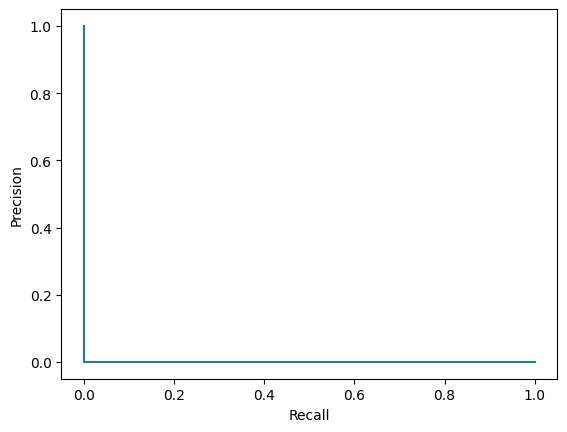

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from detectron2.utils.visualizer import Visualizer
from detectron2.data import DatasetCatalog, MetadataCatalog
from sklearn.metrics import confusion_matrix, precision_recall_curve, PrecisionRecallDisplay

def get_predictions(cfg, dataset_name):
    predictor = DefaultPredictor(cfg)
    dataset_dicts = DatasetCatalog.get(dataset_name)
    preds, gts = [], []

    for d in dataset_dicts:
        im = cv2.imread(d["file_name"])
        outputs = predictor(im)
        instances = outputs["instances"].to("cpu")
        pred_classes = instances.pred_classes.numpy()
        pred_scores = instances.scores.numpy()

        # Her bir ground truth için en yüksek skorlu tahmini al
        for anno in d["annotations"]:
            gt_class = anno["category_id"]
            gts.append(gt_class)
            matched_preds = pred_classes[pred_scores.argmax()] if len(pred_scores) > 0 else -1  # Eğer hiç tahmin yoksa -1
            preds.append(matched_preds)

    return gts, preds

# Gerçek ve tahmin edilen etiketleri al
gts, preds = get_predictions(cfg, "my_dataset_val")

# Confusion Matrix
cm = confusion_matrix(gts, preds, labels=np.unique(gts))
print("Confusion Matrix:\n", cm)

# Precision-Recall Eğrisi
precision, recall, _ = precision_recall_curve(gts, preds, pos_label=1)
disp = PrecisionRecallDisplay(precision=precision, recall=recall)
disp.plot()
plt.show()
